06 - Household Segmentation (K-prototypes)

Goal: group 2025 SHED respondents into household segments based on their
financial situation, without using the fragility target, then answer three questions:

1. Are the segments stable across bootstrap samples?
2. Do they line up with familiar demographic groups, or cut across them?
3. How fragile is each segment? (The target is only looked at after  clustering.)


Step 1 - Load data

We use the same raw 2025 file, target definition and survey weight as
`03_preprocessing` and `04_logistic_baseline`, so results line up across notebooks.

- Target:`pay_casheqv`, where 1 = could NOT cover a $400 emergency with cash or equivalent
- Weight:`weight` (proportional to `weight_pop`, so percentages are identical)

The target is only used later, to describe segments, never to build them.

In [ ]:
!pip install kmodes -q

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from kmodes.kprototypes import KPrototypes
from sklearn.metrics import adjusted_rand_score
from scipy.stats import chi2_contingency

RANDOM_STATE = 42

df = pd.read_csv("../data/SHED 2025 CSV Raw.csv", low_memory=False)

# 1 = could NOT cover $400 with cash (same as 03_preprocessing)
target = (df["pay_casheqv"] == "No").astype(int)
weight = df["weight"]

print(df.shape)
print(f"Weighted fragile rate: {np.average(target, weights=weight):.1%}")

584.50s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Step 1 - Choose clustering features

We picked features using three rules:

- Asked of everyone (no blanks).** Questions with skip logic would make clusters form
  around *who got asked what* instead of real differences.
- No target or near-target questions.** `pay_casheqv`, the EF module, `B2` and
  `atleast_okay` are left out. Otherwise the segments would just rediscover fragility.
  (`04_logistic_baseline` already flagged `B2` as near-target.)
- **No demographics.** Age, income, race, education, gender and region are held back
  so Step 5 can fairly test whether segments match them. If they went in, segments would
  match demographics by construction.

| Feature | What it captures |
|---|---|
| `B3` | Better or worse off than 12 months ago |
| `ppemploy` | Working full-time / part-time / not working |
| `I9` | How much monthly income varies |
| `GH1` | Own with mortgage / own free and clear / rent / neither |
| `FD3` | Food sufficiency in the past month |
| `C2A` | Has a credit card |
| `BNPL1` | Used Buy Now, Pay Later in the past year |
| `BK1` | Has a bank account |
| `K21_a`–`K21_f` | Retirement account, pension, stocks, savings/CD, life-insurance cash value, business/real estate |
| `pphhsize` | Household size (the only numeric feature) |

In [ ]:
# Behavior/situation questions only: no target, no near-target, no demographics
NUMERIC = ["pphhsize"]
CATEGORICAL = ["B3", "ppemploy", "I9", "GH1", "FD3", "C2A", "BNPL1", "BK1",
               "K21_a", "K21_b", "K21_c", "K21_d", "K21_e", "K21_f"]
FEATURES = NUMERIC + CATEGORICAL

EXCLUDED_ON_PURPOSE = ["pay_casheqv", "EF1", "EF2", "B2", "atleast_okay",
                       "ppage", "ppinc7", "inc_4cat_50k", "race_5cat",
                       "educ_4cat", "malefemale", "ppreg4"]

assert not set(FEATURES) & set(EXCLUDED_ON_PURPOSE)
assert df[FEATURES].notna().all().all(), "a clustering feature has blanks"
print(len(FEATURES), "features, no blanks")

15 features, no blanks


## Step 2 - Prepare the data

K-prototypes handles mixed data: it measures distance on numeric columns and counts mismatches on categorical ones. Household size is standardized so it doesn't outweigh the categorical answers. Categorical answers stay as text labels.

Survey weights are passed as `sample_weight` so the segments reflect the U.S. adult population, not the panel's makeup. We use `init="Cao"`, which is deterministic, with `n_init=4`.

In [5]:
X = df[FEATURES].copy()
# Scale household size so it doesn't overpower the categorical answers
X[NUMERIC] = (X[NUMERIC] - X[NUMERIC].mean()) / X[NUMERIC].std()

X_array = X.to_numpy(dtype=object)
CAT_IDX = [FEATURES.index(c) for c in CATEGORICAL]
w = (weight / weight.mean()).to_numpy()   # survey weights, mean = 1


def fit_segments(k, X_values=X_array, sample_weight=w, seed=RANDOM_STATE):
    model = KPrototypes(n_clusters=k, init="Cao", n_init=4,
                        random_state=seed, n_jobs=-1)
    labels = model.fit_predict(X_values, categorical=CAT_IDX,
                               sample_weight=sample_weight)
    return model, labels

## Step 2 - Choose the number of segments (k)

We fit k = 2 to 8 and plot the cost (the weighted distance from each respondent to their segment's prototype). Cost always drops as k grows, so we look for the **elbow** where adding a segment stops helping much. We also track the smallest segment's population share, because tiny segments are hard to interpret and usually unstable.

,cost,smallest segment (%)
k,,
2,33348.0,28.5
3,29761.0,26.7
4,28101.8,20.0
5,26864.4,15.8
6,25241.5,6.8
7,24350.7,1.8
8,24110.4,4.5


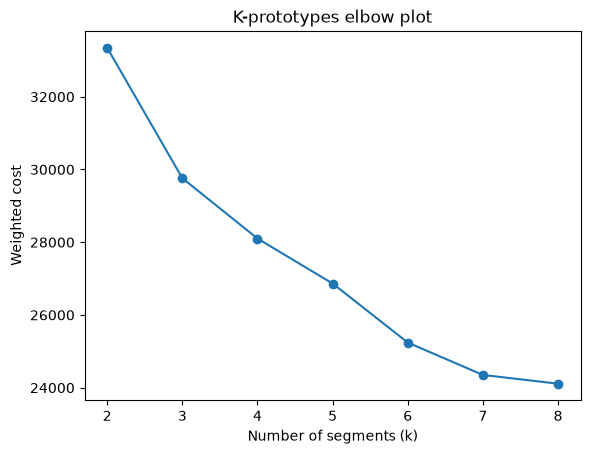

In [6]:
rows = []
for k in range(2, 9):
    model, labels = fit_segments(k)
    shares = np.bincount(labels, weights=w, minlength=k) / w.sum()
    rows.append({"k": k, "cost": model.cost_,
                 "smallest segment (%)": 100 * shares.min()})

scan = pd.DataFrame(rows).set_index("k")
display(scan.round(1))

plt.plot(scan.index, scan["cost"], "o-")
plt.xlabel("Number of segments (k)")
plt.ylabel("Weighted cost")
plt.title("K-prototypes elbow plot")
plt.show()

**Reading the elbow:** the sharpest bend is at k = 3, and the curve keeps falling steadily through k = 6. At k = 7 the smallest segment is under 2% of the population, so we only consider small k. The elbow alone doesn't settle 3 vs. 4, so Step 3 uses stability to decide.

## Step 3 - Fit final segments

We fit the final model with k = 3 (chosen by the stability check in Step 4). K-prototypes assigns segment numbers arbitrarily, so we renumber them from least to most fragile (1 = least fragile). This ordering is the only place the target touches the segments.

In [ ]:
N_SEGMENTS = 3

final_model, raw_labels = fit_segments(N_SEGMENTS)
df["raw_segment"] = raw_labels

# K-prototypes numbers are arbitrary, so renumber by fragility (1 = least fragile).
# Target is used ONLY for this ordering and the profiles, never in clustering.
raw_rates = df.groupby("raw_segment").apply(
    lambda g: np.average(target[g.index], weights=weight[g.index]))
relabel = {raw: new for new, raw in enumerate(raw_rates.sort_values().index, start=1)}
df["segment"] = df["raw_segment"].map(relabel)

df["segment"].value_counts().sort_index()

/var/folders/6x/1g6b_h6x3rggmc8pyzwyjq3w0000gn/T/ipykernel_98978/3698945140.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["raw_segment"] = raw_labels
/var/folders/6x/1g6b_h6x3rggmc8pyzwyjq3w0000gn/T/ipykernel_98978/3698945140.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["segment"] = df["raw_segment"].map(relabel)


segment
1    3050
2    3879
3    2819
4    3186
Name: count, dtype: int64

In [8]:
rows = []
for seg, g in df.groupby("segment"):
    gw = weight[g.index]
    rows.append({
        "segment": seg,
        "respondents": len(g),
        "population share (%)": 100 * gw.sum() / weight.sum(),
        "fragile rate (%)": 100 * np.average(target[g.index], weights=gw),
        "mean age": np.average(g["ppage"], weights=gw),
        "mean household size": np.average(g["pphhsize"], weights=gw),
    })
summary = pd.DataFrame(rows).set_index("segment")
overall = 100 * np.average(target, weights=weight)
print(f"Overall fragile rate: {overall:.1f}%")
display(summary.round(1))

Overall fragile rate: 36.9%


,respondents,population share (%),fragile rate (%),mean age,mean household size
segment,,,,,
1,3050,20.0,10.2,66.7,2.0
2,3879,30.0,20.9,47.2,2.0
3,2819,25.1,42.9,40.4,4.9
4,3186,24.9,71.3,43.6,2.4


## Step 3 - Segment prototypes

The prototype is the "typical" member of each segment: the most common answer for each categorical question, and the average household size. We use these to describe each segment in plain language, by situation rather than by type of person.

In [9]:
prototypes = pd.DataFrame(final_model.cluster_centroids_, columns=FEATURES)
prototypes.index = [relabel[i] for i in range(N_SEGMENTS)]
prototypes = prototypes.sort_index()
prototypes["pphhsize"] = summary["mean household size"].round(1)  # real units, not scaled
display(prototypes.T)

,1,2,3,4
pphhsize,2.0,2.0,4.9,2.4
B3,About the same,About the same,About the same,About the same
ppemploy,Not working,Working full-time,Working full-time,Not working
I9,Roughly the same amount each month,Roughly the same amount each month,Roughly the same amount each month,Roughly the same amount each month
GH1,Own your home free and clear (without a mortga...,Own your home with a mortgage or loan,Own your home with a mortgage or loan,Pay rent
FD3,Enough of the kinds of food we wanted to eat,Enough of the kinds of food we wanted to eat,Enough of the kinds of food we wanted to eat,"Enough, but not always the kinds of food we wa..."
C2A,Yes,Yes,Yes,Yes
BNPL1,No,No,No,No
BK1,Yes,Yes,Yes,Yes
K21_a,Yes,Yes,Yes,No


## Step 3 - Fragility by segment

Weighted share of each segment that couldn't cover a $400 emergency with cash, compared with the overall rate of 36.9% (dashed line). Big gaps between segments mean the clustering found groups that differ in resilience, even though it never saw the target.

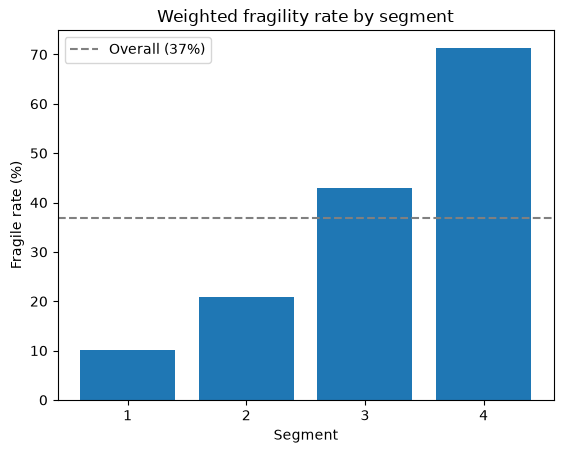

In [10]:
plt.bar(summary.index.astype(str), summary["fragile rate (%)"])
plt.axhline(overall, linestyle="--", color="gray", label=f"Overall ({overall:.0f}%)")
plt.xlabel("Segment")
plt.ylabel("Fragile rate (%)")
plt.title("Weighted fragility rate by segment")
plt.legend()
plt.show()

## Step 3 - Stability check (bootstrap)

A segment is only useful if it shows up again when the data changes a little. We test this by refitting K-prototypes on 30 **bootstrap resamples** (respondents drawn with replacement, keeping their survey weights). Each refit model then labels all 12,934 respondents, and we compare those labels with the segments fit on the full data.

- **Adjusted Rand index (ARI):** overall agreement. 1 = identical, 0 = chance. It ignores segment numbering, so no relabeling is needed.
- **Jaccard per segment:** for each original segment, the overlap with its closest match in the refit. Rule of thumb (Hennig, 2007): above 0.75 is stable, 0.6–0.75 is a pattern, below 0.5 means the segment dissolves.

We run this for both candidate values, k = 3 and k = 4. It takes about 5 minutes.

In [11]:

def jaccard_per_segment(ref, other, k):
    # For each reference segment, best overlap with any segment in `other`
    return [max(((ref == s) & (other == c)).sum() / ((ref == s) | (other == c)).sum()
                for c in np.unique(other))
            for s in range(k)]

In [12]:
N_BOOTSTRAP = 30
rng = np.random.default_rng(RANDOM_STATE)
boot_results = {}
rows = []

for k in [3, 4]:
    _, ref = fit_segments(k)
    ari, jac = [], []
    for b in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(w), len(w))          # draw rows WITH replacement
        boot_model, _ = fit_segments(k, X_array[idx], w[idx])
        boot_labels = boot_model.predict(X_array, categorical=CAT_IDX)  # label everyone
        ari.append(adjusted_rand_score(ref, boot_labels))
        jac.append(jaccard_per_segment(ref, boot_labels, k))
    boot_results[k] = np.array(jac)
    rows.append({"k": k,
                 "ARI mean": np.mean(ari),
                 "ARI min": np.min(ari),
                 "worst segment Jaccard": np.mean(jac, axis=0).min()})

stability = pd.DataFrame(rows).set_index("k")
display(stability.round(3))

,ARI mean,ARI min,worst segment Jaccard
k,,,
3,0.966,0.792,0.963
4,0.591,0.335,0.608


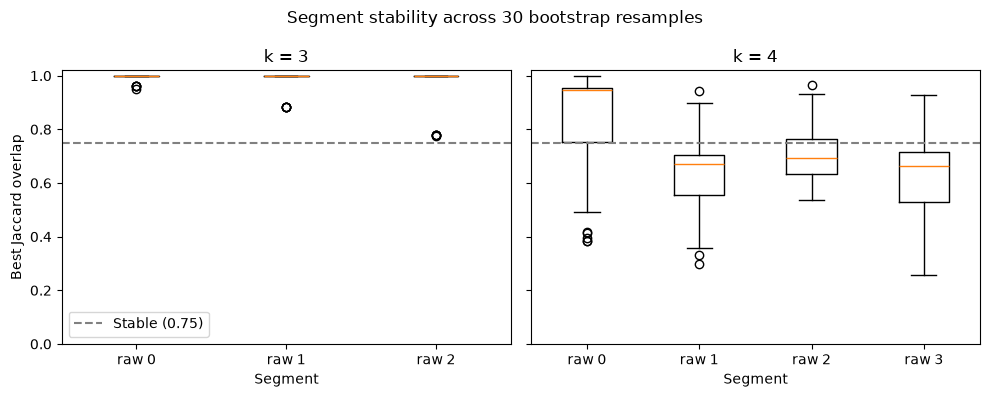

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, k in zip(axes, [3, 4]):
    ax.boxplot(boot_results[k].T.tolist(), tick_labels=[f"raw {i}" for i in range(k)])
    ax.axhline(0.75, linestyle="--", color="gray", label="Stable (0.75)")
    ax.set(title=f"k = {k}", xlabel="Segment", ylim=(0, 1.02))
axes[0].set_ylabel("Best Jaccard overlap")
axes[0].legend(loc="lower left")
fig.suptitle(f"Segment stability across {N_BOOTSTRAP} bootstrap resamples")
plt.tight_layout()
plt.show()

Result: k = 3 is highly stable: mean ARI 0.966, and every segment keeps an average Jaccard of at least 0.96. k = 4 gives a more appealing fragility split (about 10 / 21 / 43 / 71%) but doesn't replicate: mean ARI 0.591, worst resample 0.335, and its weakest segment averages only 0.61 Jaccard. We choose 
k = 3. Stable segments we can defend are worth more than a sharper split that changes between samples.



## Step 5 - Compare segments with demographics

Demographics weren't used to build the segments, so we can check whether segments line up with familiar groupings or cut across them.

Cramér's V summarizes the strength of the link: 0 = knowing someone's segment says nothing about their group, 1 = it determines it. Rough guide: below 0.1 is weak, 0.1–0.3 moderate, above 0.3 strong.

Auditing whether segments overlap with protected groups is a different activity from targeting by group. We do only the first.

In [14]:
DEMOGRAPHICS = {
    "inc_4cat_50k": "Income",
    "ppagecat": "Age group",
    "educ_4cat": "Education",
    "race_5cat": "Race and ethnicity",
    "malefemale": "Gender",
    "ppreg4": "Census region",
    "ppmsacat": "Metro / non-metro",
}


def weighted_crosstab(rows, cols, weights):
    return pd.crosstab(rows, cols, values=weights, aggfunc="sum").fillna(0)


def cramers_v(x, y, weights):
    # 0 = segment tells you nothing about the group, 1 = it fully determines it
    table = weighted_crosstab(x, y, weights)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

## Step 5 - Segment makeup by demographic group

Each table shows the weighted makeup of every segment next to the whole population ("All"). Large differences from the "All" column mean that group is over- or under-represented in the segment.

In [15]:
demo_rows = []
for col, label in DEMOGRAPHICS.items():
    makeup = weighted_crosstab(df[col], df["segment"], w)
    makeup = 100 * makeup / makeup.sum()
    makeup["All"] = 100 * df.groupby(col)["weight"].sum() / df["weight"].sum()
    v = cramers_v(df[col], df["segment"], w)
    demo_rows.append({"demographic": label, "Cramér's V": v})
    print(f"\n{label} (Cramér's V = {v:.2f}), % of each segment")
    display(makeup.round(1))

demo_assoc = (pd.DataFrame(demo_rows).set_index("demographic")
              .sort_values("Cramér's V"))


Income (Cramér's V = 0.31), % of each segment


segment,1,2,3,4,All
inc_4cat_50k,,,,,
"$100,000 or more",49.8,60.1,42.9,8.3,40.8
"$25,000–$49,999",11.1,9.6,14.0,26.5,15.2
"$50,000–$99,999",34.7,26.1,23.0,20.7,25.7
"Less than $25,000",4.4,4.3,20.1,44.6,18.3



Age group (Cramér's V = 0.36), % of each segment


segment,1,2,3,4,All
ppagecat,,,,,
18-24,1.9,5.4,16.7,17.2,10.5
25-34,3.0,20.4,16.9,21.4,16.3
35-44,3.1,20.0,31.2,19.5,19.3
45-54,5.4,17.1,19.9,12.3,14.3
55-64,19.6,24.9,9.7,12.2,16.9
65-74,37.8,9.2,4.2,11.6,14.3
75+,29.1,3.0,1.4,5.9,8.5



Education (Cramér's V = 0.21), % of each segment


segment,1,2,3,4,All
educ_4cat,,,,,
Bachelor's degree or more,42.5,53.6,38.0,13.8,37.6
High school degree or GED,25.4,16.8,25.4,38.8,26.2
Less than a high school degree,2.1,1.5,6.1,15.1,6.2
Some college/technical or associates degree,30.1,28.2,30.4,32.3,30.1


... (4 outputs left out)


Census region (Cramér's V = 0.03), % of each segment


segment,1,2,3,4,All
ppreg4,,,,,
Midwest,20.5,21.0,19.8,20.1,20.4
Northeast,19.5,17.9,15.3,16.3,17.2
South,37.2,37.7,38.1,41.5,38.6
West,22.7,23.4,26.8,22.1,23.8



Metro / non-metro (Cramér's V = 0.06), % of each segment


segment,1,2,3,4,All
ppmsacat,,,,,
Metro,85.3,89.2,87.8,84.0,86.8
Non-Metro,14.7,10.8,12.2,16.0,13.2


## Step 5 - Strength of association

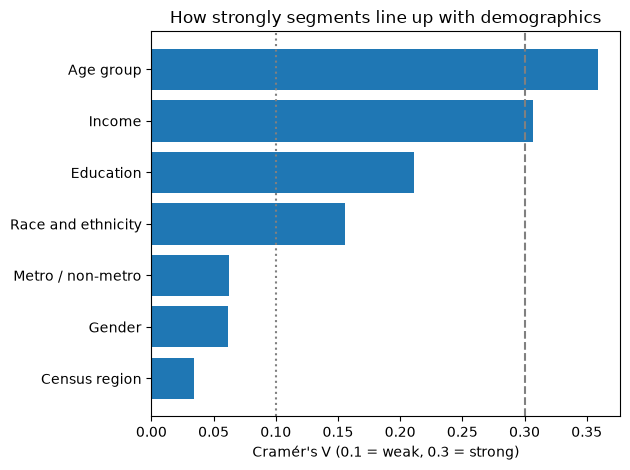

In [16]:
plt.barh(demo_assoc.index, demo_assoc["Cramér's V"])
plt.axvline(0.1, linestyle=":", color="gray")
plt.axvline(0.3, linestyle="--", color="gray")
plt.xlabel("Cramér's V (0.1 = weak, 0.3 = strong)")
plt.title("How strongly segments line up with demographics")
plt.tight_layout()
plt.show()

# Findings

**Setup.** K-prototypes on 15 behavior/situation questions (housing, food sufficiency,
credit, BNPL, banking, six asset types, employment, income volatility, household size).
The target, near-target questions (`B2`, EF module) and all demographics were left out,
so the demographic comparison is a fair test.

**Choice of k = 3.** The elbow bends at k = 3. k = 4 looked appealing (fragile rates
10 / 21 / 43 / 71%) but did not replicate: bootstrap ARI 0.66, worst run 0.35.
k = 3 is highly stable: bootstrap ARI 0.98, every segment's Jaccard ≥ 0.98.

**The three segments** (weighted, overall fragile rate 37%):

| Segment | Share | Fragile | Situation |
|---|---|---|---|
| 1 | 45% | 16% | Working full-time, mortgage, retirement + investments + savings |
| 2 | 27% | 44% | Larger households, working, retirement savings but no investments |
| 3 | 29% | 62% | Renting, not working, no retirement, investment or savings accounts |

**Demographics: segments track income but cut across age.**
- Strongest link is income (Cramér's V = 0.35); education (0.25) and race (0.18) are moderate.
- Age is only moderate (0.27): the most fragile segment includes 25% of people 65+,
  and 15% of the least fragile segment earns under $50k.
- Gender, region and metro status are essentially unrelated (V ≈ 0.05).

**Limits.** Segments describe financial situations, not types of people. kmodes
weights are used in fitting, but cost and prototypes are approximate. Results are
for 2025 only.